In [1]:
import keras
import numpy as np
import tensorflow as tf
from keras import ops
from keras.layers import Dense, RandomRotation, RandomFlip, RandomZoom
from keras.models import Model, Sequential
from keras_cv.layers import RandomShear
import matplotlib.pyplot as plt
import albumentations as A
print(keras.__version__)

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


3.0.4


In [5]:
def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

In [3]:
test_line = "Data\Glomanthang\Lines\I2KG2290430219_1.jpg"

tf_img = tf.io.read_file(test_line)
tf_img = tf.image.decode_jpeg(tf_img)
print(tf_img.shape)

(83, 2636, 3)


In [19]:
from natsort import natsorted
from glob import glob

dataset_path = "D:/Datasets/Tibetan/LhasaKanjur/LhasaKanjurProdigy_v1_reviewed"
all_images = natsorted(glob(f"{dataset_path}/lines/*.jpg"))
all_labels = natsorted(glob(f"{dataset_path}/transcriptions/*.txt"))

print(f"All Images: {len(all_images)}, All Labels: {len(all_images)}")

All Images: 160774, All Labels: 160774


In [1]:
train_transform = A.Compose(
[
        #A.ShiftScaleRotate(shift_limit=0.02, scale_limit=0.01, rotate_limit=1, p=0.5), 
        A.Affine(scale=None, translate_percent=None, translate_px=None, rotate=[0, 0], shear={"x": (-10, 10), "y": 0}, interpolation=1, mask_interpolation=0, cval=0, cval_mask=0, mode=0, fit_output=False, keep_ratio=False, rotate_method='largest_box', always_apply=True, p=0.5),
        #A.RandomBrightnessContrast(p=0.1),
        #A.Downscale(scale_min=0.5, scale_max=0.5, interpolation=None, always_apply=False, p=0.5),
        A.Emboss (alpha=(0.2, 0.5), strength=(0.2, 0.7), always_apply=False, p=0.5),
        A.GaussNoise(var_limit=(10.0, 50.0), mean=0, per_channel=True, always_apply=False, p=0.5),
        A.PixelDropout(dropout_prob=0.02, per_channel=False, drop_value=0, mask_drop_value=None, always_apply=False, p=0.5),
        A.RandomGravel (gravel_roi=(0.2, 0.4, 0.9, 0.9), number_of_patches=2, always_apply=False, p=0.5),
        #A.RandomRain (slant_lower=-10, slant_upper=10, drop_length=20, drop_width=1, drop_color=(200, 200, 200), blur_value=2, brightness_coefficient=0.7, rain_type=None, always_apply=False, p=0.5)
        A.AdvancedBlur (blur_limit=(3, 7), sigmaX_limit=(0.2, 1.0), sigmaY_limit=(0.2, 1.0), rotate_limit=90, beta_limit=(0.5, 8.0), noise_limit=(0.9, 1.1), always_apply=False, p=0.5)
        
    ]
)

NameError: name 'A' is not defined

In [17]:


x_shear = random.randint(-10, 10)
shearing = {"x": x_shear, "y": 0}




train_img = cv2.imread(test_line)

aug = train_transform(image=tf_img)
aug_img = aug["image"]
show_image(aug_img)

TypeError: image must be numpy array type

(83, 2636, 3)


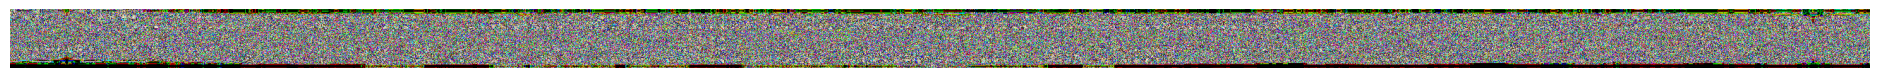

In [145]:
data_aug = keras.Sequential(
    [
        RandomFlip("horizontal"),
        #RandomRotation(0.1),
        RandomZoom(0.1),
    ]
)

y = data_aug(tf_img)
print(y.shape)
y = y.numpy()
y *= 255
y = y.astype(np.uint8)
show_image((y * 255).astype(np.uint8))

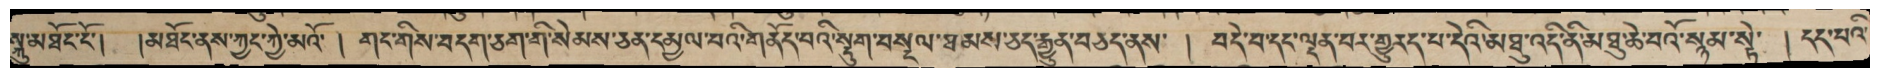

In [115]:
show_image(tf_img.numpy())

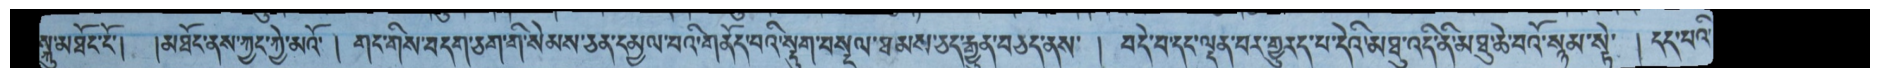

In [111]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

im = cv2.imread(test_line)
H, W, _ = im.shape

M2 = np.float32([[0.9, 0, 0], [0, 1.1, 0]])
M2[0,2] = (-M2[0,1] * H/2) + H*0.5
M2[1,2] = (-M2[1,0] * W/2)
aff2 = cv2.warpAffine(im, M2, (W, H))

show_image(aff2, cmap="gray")


In [ ]:
def transform(
    images: TensorLike,
    transforms: TensorLike,
    interpolation: str = "nearest",
    fill_mode: str = "constant",
    output_shape: Optional[list] = None,
    name: Optional[str] = None,
    fill_value: TensorLike = 0.0,
) -> tf.Tensor:
    """Applies the given transform(s) to the image(s).

    Args:
      images: A tensor of shape (num_images, num_rows, num_columns,
        num_channels) (NHWC), (num_rows, num_columns, num_channels) (HWC), or
        (num_rows, num_columns) (HW).
      transforms: Projective transform matrix/matrices. A vector of length 8 or
        tensor of size N x 8. If one row of transforms is
        [a0, a1, a2, b0, b1, b2, c0, c1], then it maps the *output* point
        `(x, y)` to a transformed *input* point
        `(x', y') = ((a0 x + a1 y + a2) / k, (b0 x + b1 y + b2) / k)`,
        where `k = c0 x + c1 y + 1`. The transforms are *inverted* compared to
        the transform mapping input points to output points. Note that
        gradients are not backpropagated into transformation parameters.
      interpolation: Interpolation mode.
        Supported values: "nearest", "bilinear".
      fill_mode: Points outside the boundaries of the input are filled according
        to the given mode (one of `{'constant', 'reflect', 'wrap', 'nearest'}`).
        - *reflect*: `(d c b a | a b c d | d c b a)`
          The input is extended by reflecting about the edge of the last pixel.
        - *constant*: `(k k k k | a b c d | k k k k)`
          The input is extended by filling all values beyond the edge with the
          same constant value k = 0.
        - *wrap*: `(a b c d | a b c d | a b c d)`
          The input is extended by wrapping around to the opposite edge.
        - *nearest*: `(a a a a | a b c d | d d d d)`
          The input is extended by the nearest pixel.
      fill_value: a float represents the value to be filled outside the
        boundaries when `fill_mode` is "constant".
      output_shape: Output dimesion after the transform, [height, width].
        If None, output is the same size as input image.

      name: The name of the op.

    Returns:
      Image(s) with the same type and shape as `images`, with the given
      transform(s) applied. Transformed coordinates outside of the input image
      will be filled with zeros.

    Raises:
      TypeError: If `image` is an invalid type.
      ValueError: If output shape is not 1-D int32 Tensor.
    """
    with tf.name_scope(name or "transform"):
        image_or_images = tf.convert_to_tensor(images, name="images")
        transform_or_transforms = tf.convert_to_tensor(
            transforms, name="transforms", dtype=tf.dtypes.float32
        )
        if image_or_images.dtype.base_dtype not in _IMAGE_DTYPES:
            raise TypeError("Invalid dtype %s." % image_or_images.dtype)
        images = img_utils.to_4D_image(image_or_images)
        original_ndims = img_utils.get_ndims(image_or_images)

        if output_shape is None:
            output_shape = tf.shape(images)[1:3]

        output_shape = tf.convert_to_tensor(
            output_shape, tf.dtypes.int32, name="output_shape"
        )

        if not output_shape.get_shape().is_compatible_with([2]):
            raise ValueError(
                "output_shape must be a 1-D Tensor of 2 elements: "
                "new_height, new_width"
            )

        if len(transform_or_transforms.get_shape()) == 1:
            transforms = transform_or_transforms[None]
        elif transform_or_transforms.get_shape().ndims is None:
            raise ValueError("transforms rank must be statically known")
        elif len(transform_or_transforms.get_shape()) == 2:
            transforms = transform_or_transforms
        else:
            transforms = transform_or_transforms
            raise ValueError(
                "transforms should have rank 1 or 2, but got rank %d"
                % len(transforms.get_shape())
            )

        fill_value = tf.convert_to_tensor(
            fill_value, dtype=tf.float32, name="fill_value"
        )
        output = tf.raw_ops.ImageProjectiveTransformV3(
            images=images,
            transforms=transforms,
            output_shape=output_shape,
            interpolation=interpolation.upper(),
            fill_mode=fill_mode.upper(),
            fill_value=fill_value,
        )
        return img_utils.from_4D_image(output, original_ndims)


def shear_x(image: TensorLike, level: float, replace: TensorLike) -> TensorLike:
    """Perform shear operation on an image (x-axis).

    Args:
        image: A 3D image `Tensor`.
        level: A float denoting shear element along y-axis
        replace: A one or three value 1D tensor to fill empty pixels.
    Returns:
        Transformed image along X or Y axis, with space outside image
        filled with replace.
    """
    # Shear parallel to x axis is a projective transform
    # with a matrix form of:
    # [1  level
    #  0  1].
    image = transform(wrap(image), [1.0, level, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0])
    return unwrap(image, replace)